In [21]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display 

In [22]:
class State(TypedDict):
    name : str
    issue : str
    description : str
    additional_info : str
    urgency : str
    is_valid : bool
    response : str
    department : str

In [23]:
def receive_ticket(state: State):
    print(f"Received ticket from {state['name']}")

def validate_ticket(state: State):
    if len(state['description']) > 10:
        return {"is_valid": True}
    return {"is_valid": False}

def classify_issue(state: State):
    issue = state['issue'].lower()
    if any (word in issue for word in ['payment', 'refund', 'billing', 'charge']):
        category = 'billing'
    elif any (word in issue for word in ['error', 'bug', 'login', 'crash', 'technical']):
        category = 'technical'
    else:
        category = 'general'    
    return {"department": category}

def billing(state: State):
    return {"department" : "Billing Department"}

def technical(state: State):
    return {"department" : "Technical Support"}

def general(state: State):
    return {"department" : "General Support"}

def set_priority(state: State):
    if state['urgency'].lower() in ['high', 'urgent', 'critical']:
        priority = 'High'
    else:
        priority = 'Normal'
    return {"priority": priority}

def generate_response(state: State):
    if not state['is_valid']:
        return {"response": "Your ticket is invalid. Please provide a detailed description."}
    else:
        return {"response": f"Thank you for your ticket. It has been assigned to the {state['department']}."}

In [24]:
def check_validation(state: State):
    if state['is_valid']:
        return "valid"
    else: 
        return "invalid"
    
def check_department(state: State):
    if state['department'] == 'billing':
        return "billing"
    elif state['department'] == 'technical':
        return "technical"
    else:
        return "general"

In [25]:
graph = StateGraph(State)

In [26]:
graph.add_node("receive_ticket", receive_ticket)
graph.add_node("validate_ticket", validate_ticket)
graph.add_node("classify_issue", classify_issue)
graph.add_node("billing", billing)
graph.add_node("technical", technical)
graph.add_node("general", general)
graph.add_node("set_priority", set_priority)
graph.add_node("generate_response", generate_response)

In [27]:
graph.add_edge(START, "receive_ticket")
graph.add_edge("receive_ticket", "validate_ticket")
graph.add_conditional_edges("validate_ticket", check_validation, {
    "valid": "classify_issue",
    "invalid": "generate_response"
})
graph.add_conditional_edges("classify_issue", check_department, {
    "billing": "billing",
    "technical": "technical",
    "general": "general"
})
graph.add_edge("billing", "set_priority")
graph.add_edge("technical", "set_priority")
graph.add_edge("general", "set_priority")
graph.add_edge("set_priority", "generate_response")
graph.add_edge("generate_response", END)

In [28]:
graph_builder = graph.compile()

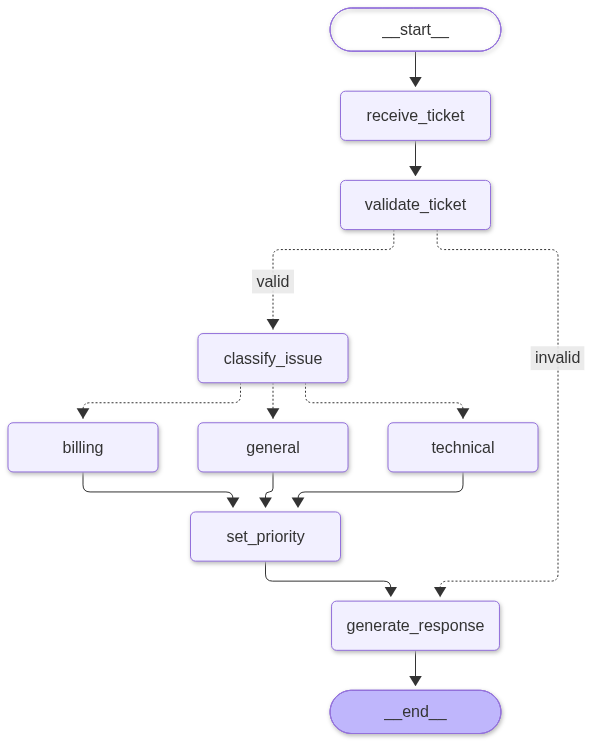

In [29]:
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [32]:
graph_builder.invoke({
    "name" : "John Doe",
    "issue" : "payment failed",
    "description" : "I tried to make a payment but it failed.",
    "additional_info" : "Money was deducted from my bank account but order was not placed.",
    "urgency" : "high",
    "is_valid" : False,
    "response" : "", 
    "department" : ""
})

Received ticket from John Doe


{'name': 'John Doe',
 'issue': 'payment failed',
 'description': 'I tried to make a payment but it failed.',
 'additional_info': 'Money was deducted from my bank account but order was not placed.',
 'urgency': 'high',
 'is_valid': True,
 'response': 'Thank you for your ticket. It has been assigned to the Billing Department.',
 'department': 'Billing Department'}